# 01_03 Poisson

**Learning objectives**
- See the Poisson as the limit of the Binomial for rare events, and derive it step by step.
- Derive its mean, variance, PGF/MGF, and the additivity property.
- Connect it to the Poisson process and the Exponential waiting time.
- Check a Poisson model against real data (Premier League goals) by eye and with a chi-square test.

**Prerequisites:** [01_01 Bernoulli and Binomial](01_01_bernoulli_binomial.ipynb), [01_02 Geometric and Negative Binomial](01_02_geometric_negative_binomial.ipynb) (for the overdispersion discussion).

## 1. Setup

All imports in one cell, seeded generator for reproducibility. The football CSV is read later from `../data/` (run `../data/download_data.py` if it is missing).

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Binomial($n,p$):** number of successes in $n$ independent trials, $P(X=k)=\binom nk p^k(1-p)^{n-k}$, mean $np$.
- **Exponential series:** $e^{\lambda}=\sum_{k=0}^{\infty}\lambda^k/k!$.
- **Limit:** $\lim_{n\to\infty}(1-\lambda/n)^n=e^{-\lambda}$.
- **Expectation** is linear; for independent variables variances add.

## 3. Intuition and story

Events happen at random moments: calls to a call center, requests to a server, goals in a football match, typos on a page. If events are **independent**, occur at a **constant average rate**, and **cannot happen at exactly the same instant**, the number of events in a fixed window is **Poisson($\lambda$)**, where $\lambda$ is the average number of events per window.

Picture the window cut into $n$ tiny slices, each with a very small chance $p=\lambda/n$ of containing an event. The count is Binomial($n,\lambda/n$). Letting the slices shrink ($n\to\infty$) gives the Poisson.

## 4. Formal definition

**Poisson($\lambda$):** support $k\in\{0,1,2,\dots\}$, parameter $\lambda>0$ (mean number of events in the window).
$$P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!},\qquad F(k)=e^{-\lambda}\sum_{j=0}^{k}\frac{\lambda^j}{j!}.$$
Rates scale with the window: if events arrive at rate $\mu$ per hour, the count in $t$ hours is Poisson($\mu t$).

## 5. Derivations

### 5.1 Limit of the Binomial
Let $X_n\sim\text{Bin}(n,\lambda/n)$. For fixed $k$:
$$P(X_n=k)=\frac{n(n-1)\cdots(n-k+1)}{k!}\Big(\frac\lambda n\Big)^k\Big(1-\frac\lambda n\Big)^{n-k}
=\frac{\lambda^k}{k!}\cdot\underbrace{\frac{n(n-1)\cdots(n-k+1)}{n^k}}_{\to1}\cdot\underbrace{\Big(1-\frac\lambda n\Big)^n}_{\to e^{-\lambda}}\cdot\underbrace{\Big(1-\frac\lambda n\Big)^{-k}}_{\to1}.$$
The first factor has $k$ terms each of the form $(n-j)/n\to1$. Taking $n\to\infty$ gives $P(X=k)\to e^{-\lambda}\lambda^k/k!$.

### 5.2 Normalization
$\sum_{k=0}^\infty e^{-\lambda}\lambda^k/k!=e^{-\lambda}e^{\lambda}=1$.

### 5.3 Mean
$$E[X]=\sum_{k=1}^\infty k\frac{e^{-\lambda}\lambda^k}{k!}=\lambda e^{-\lambda}\sum_{k=1}^\infty\frac{\lambda^{k-1}}{(k-1)!}=\lambda e^{-\lambda}e^{\lambda}=\lambda.$$

### 5.4 Variance
First $E[X(X-1)]=\sum_{k=2}^\infty k(k-1)\frac{e^{-\lambda}\lambda^k}{k!}=\lambda^2e^{-\lambda}\sum_{k=2}^\infty\frac{\lambda^{k-2}}{(k-2)!}=\lambda^2$. Then
$$\mathrm{Var}(X)=E[X(X-1)]+E[X]-E[X]^2=\lambda^2+\lambda-\lambda^2=\lambda.$$
**Mean = variance = $\lambda$.** This is the signature of the Poisson and the first thing to check on real data.

### 5.5 PGF and MGF
$$G(s)=\sum_k s^k\frac{e^{-\lambda}\lambda^k}{k!}=e^{-\lambda}e^{\lambda s}=e^{\lambda(s-1)},\qquad M(t)=e^{\lambda(e^t-1)}.$$

### 5.6 Additivity
If $X\sim\text{Poi}(\lambda_1)$ and $Y\sim\text{Poi}(\lambda_2)$ are independent, $G_{X+Y}(s)=e^{\lambda_1(s-1)}e^{\lambda_2(s-1)}=e^{(\lambda_1+\lambda_2)(s-1)}$, so $X+Y\sim\text{Poi}(\lambda_1+\lambda_2)$. (Two call queues with rates 5 and 7 per hour give 12 per hour.)

### 5.7 Mode, skewness, kurtosis (stated)
Mode $=\lfloor\lambda\rfloor$ (two modes $\lambda-1$ and $\lambda$ when $\lambda$ is an integer). Skewness $=1/\sqrt\lambda$, excess kurtosis $=1/\lambda$. Both vanish as $\lambda$ grows, so large-$\lambda$ Poissons look Normal.

## 6. Properties and relationships

- **Binomial limit:** Bin($n,p$) with large $n$, small $p$ is close to Poisson($np$).
- **Normal limit:** for $\lambda\gtrsim 20$, Poisson($\lambda$) is close to Normal($\lambda,\lambda$).
- **Poisson process and Exponential:** if events form a Poisson process with rate $\mu$, the counts in disjoint windows are independent Poisson, and the **waiting time between events is Exponential($\mu$)**, since $P(\text{no event in }t)=e^{-\mu t}$ (this is the Poisson PMF at $k=0$ with $\lambda=\mu t$). Full treatment in Module 02.
- **Thinning:** keeping each event independently with probability $q$ turns Poisson($\lambda$) into Poisson($q\lambda$).
- **Conditioning:** given $X+Y=n$ for independent Poissons, $X\sim\text{Bin}(n,\lambda_1/(\lambda_1+\lambda_2))$.
- **Overdispersion:** if the variance is larger than the mean, use Negative Binomial (lesson 01_02).

## 7. 2D visuals

### 7.1 PMF and CDF
Poisson with lambda = 4: the PMF peaks near the mean, the CDF is the running total.

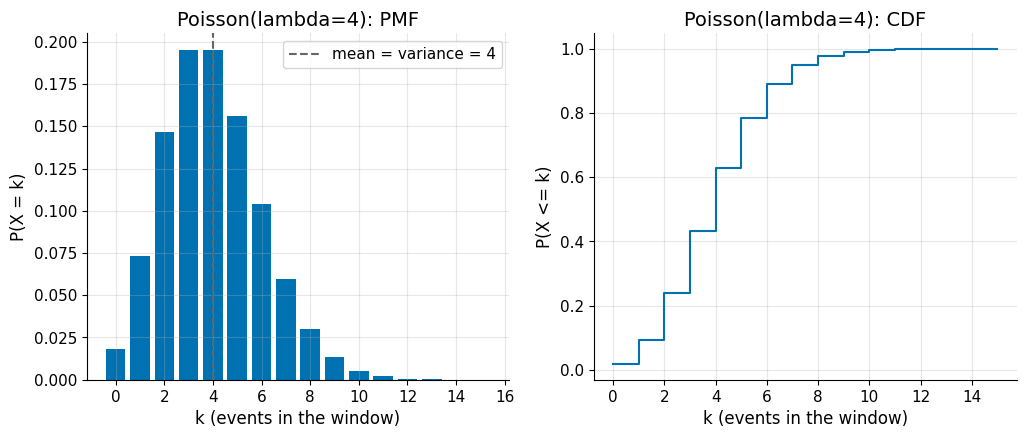

In [2]:
lam = 4          # lambda: average number of events per window
dist = stats.poisson(mu=lam)
k_values = np.arange(0, 16)

fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pmf.bar(k_values, dist.pmf(k_values), color=MAIN)
ax_pmf.axvline(lam, color=NEUTRAL, linestyle="--", label="mean = variance = 4")
ax_pmf.set_title("Poisson(lambda=4): PMF")
ax_pmf.set_xlabel("k (events in the window)")
ax_pmf.set_ylabel("P(X = k)")
ax_pmf.legend()

ax_cdf.step(k_values, dist.cdf(k_values), where="post", color=MAIN)
ax_cdf.set_title("Poisson(lambda=4): CDF")
ax_cdf.set_xlabel("k (events in the window)")
ax_cdf.set_ylabel("P(X <= k)")
plt.show()

### 7.2 Effect of lambda
Small lambda: mass at 0 and 1, strong right skew. Larger lambda: shifts right, widens (variance = lambda), becomes symmetric.

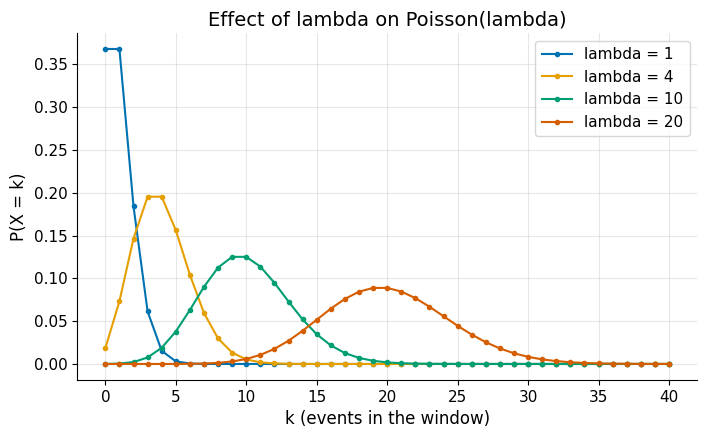

In [3]:
k_values = np.arange(0, 41)
fig, ax = plt.subplots()
for lam_value, color in zip([1, 4, 10, 20], COLORS):
    ax.plot(k_values, stats.poisson(lam_value).pmf(k_values), "o-", markersize=3, color=color, label=f"lambda = {lam_value}")
ax.set_title("Effect of lambda on Poisson(lambda)")
ax.set_xlabel("k (events in the window)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.3 Binomial to Poisson: the limit in action
We fix the mean at 3 (n times p = 3) and increase n. The Binomial bars approach the Poisson curve.

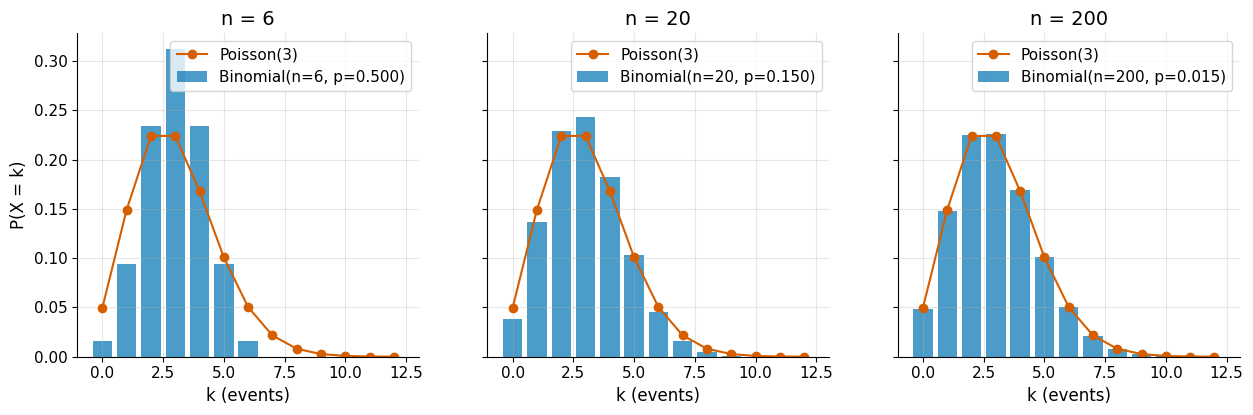

In [4]:
lam = 3
k_values = np.arange(0, 13)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, n in zip(axes, [6, 20, 200]):
    ax.bar(k_values, stats.binom(n, lam / n).pmf(k_values), color=MAIN, alpha=0.7, label=f"Binomial(n={n}, p={lam/n:.3f})")
    ax.plot(k_values, stats.poisson(lam).pmf(k_values), "o-", color=HIGHLIGHT, label="Poisson(3)")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("k (events)")
    ax.legend()
axes[0].set_ylabel("P(X = k)")
plt.show()

## 8. 3D visuals

### 8.1 PMF over (k, lambda)
The ridge follows k = lambda and flattens as lambda grows.

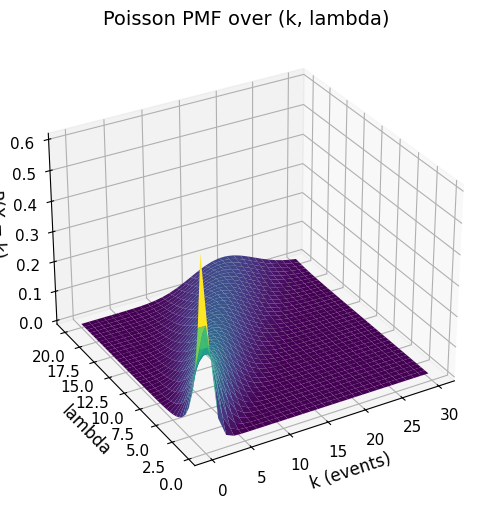

In [5]:
k_values = np.arange(0, 31)
lam_values = np.linspace(0.5, 20, 40)
K, L = np.meshgrid(k_values, lam_values)
Z = stats.poisson.pmf(K, L)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(K, L, Z, cmap="viridis", edgecolor="none")
ax.set_title("Poisson PMF over (k, lambda)")
ax.set_xlabel("k (events)")
ax.set_ylabel("lambda")
ax.set_zlabel("P(X = k)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.2 Binomial to Poisson convergence surface
For lambda = 3, the surface shows the absolute difference between the Binomial(n, 3/n) PMF and the Poisson(3) PMF, over (k, n). It flattens toward zero as n grows.

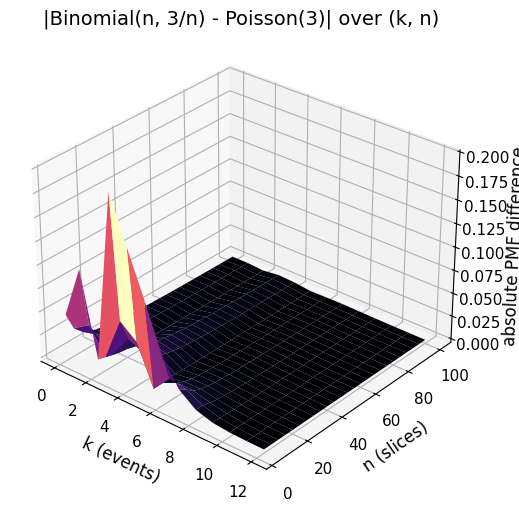

In [6]:
lam = 3
k_values = np.arange(0, 13)
n_values = np.arange(4, 101, 4)
K, N = np.meshgrid(k_values, n_values)
difference = np.abs(stats.binom.pmf(K, N, lam / N) - stats.poisson.pmf(K, lam))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(K, N, difference, cmap="magma", edgecolor="none")
ax.set_title("|Binomial(n, 3/n) - Poisson(3)| over (k, n)")
ax.set_xlabel("k (events)")
ax.set_ylabel("n (slices)")
ax.set_zlabel("absolute PMF difference")
ax.view_init(elev=30, azim=-50)
plt.show()

### 8.3 Interactive Plotly version
The PMF surface of 8.1; rotate and hover to read values.

In [7]:
fig = go.Figure(go.Surface(x=np.arange(0, 31), y=np.linspace(0.5, 20, 40), z=Z, colorscale="Viridis"))
fig.update_layout(title="Poisson PMF over (k, lambda)", width=750, height=550,
                  scene=dict(xaxis_title="k (events)", yaxis_title="lambda", zaxis_title="P(X = k)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PMF
20,000 draws from Poisson(4) against the PMF.

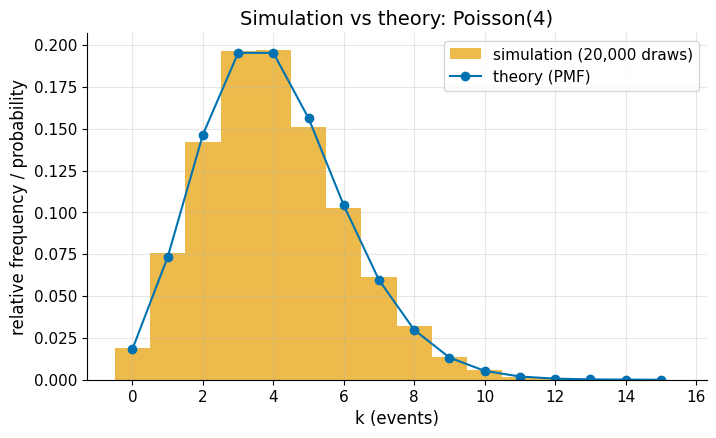

sample mean 4.006  sample variance 4.091  (both should be near 4)


In [8]:
lam = 4
samples = rng.poisson(lam=lam, size=20_000)
k_values = np.arange(0, 16)

fig, ax = plt.subplots()
ax.hist(samples, bins=np.arange(0, 17) - 0.5, density=True, color=SIM, alpha=0.7, label="simulation (20,000 draws)")
ax.plot(k_values, stats.poisson(lam).pmf(k_values), "o-", color=MAIN, label="theory (PMF)")
ax.set_title("Simulation vs theory: Poisson(4)")
ax.set_xlabel("k (events)")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()
print("sample mean", samples.mean().round(3), " sample variance", samples.var().round(3), " (both should be near 4)")

### 9.2 Running mean converges to lambda

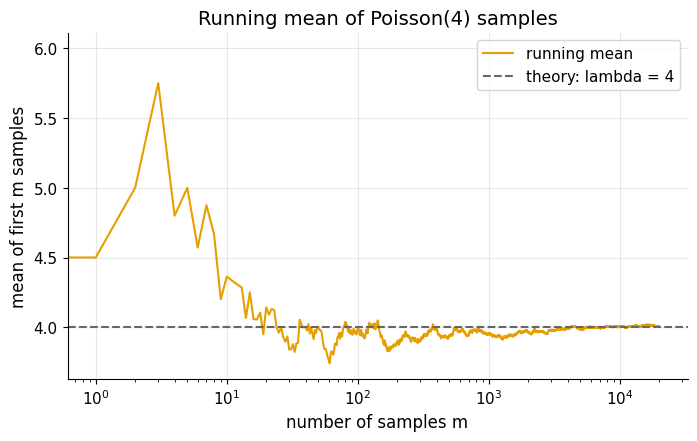

In [9]:
running_mean = np.cumsum(samples) / np.arange(1, len(samples) + 1)

fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(lam, color=NEUTRAL, linestyle="--", label="theory: lambda = 4")
ax.set_title("Running mean of Poisson(4) samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.set_xscale("log")
ax.legend()
plt.show()

### 9.3 Poisson process: exponential gaps (preview)
We place events with Exponential(1) gaps (rate 1 per unit time) and count events in each unit-length window. The counts follow Poisson(1).

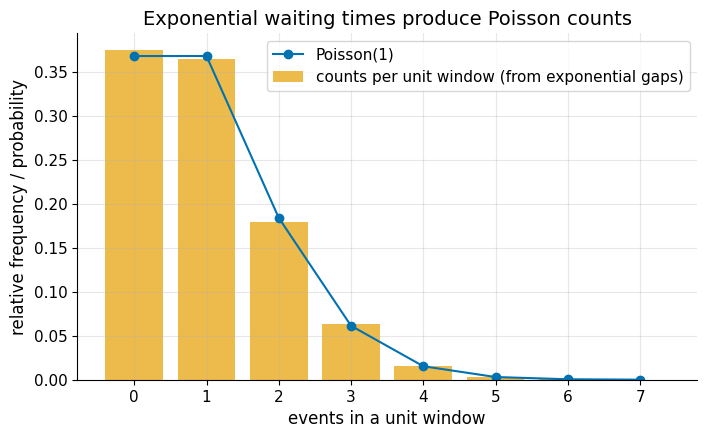

In [10]:
gaps = rng.exponential(scale=1.0, size=60_000)       # time between events, mean 1
event_times = np.cumsum(gaps)
n_windows = 20_000
counts_per_window = np.bincount(event_times.astype(int))[:n_windows]

k_values = np.arange(0, 8)
observed = np.bincount(counts_per_window, minlength=8)[:8] / len(counts_per_window)
fig, ax = plt.subplots()
ax.bar(k_values, observed, color=SIM, alpha=0.7, label="counts per unit window (from exponential gaps)")
ax.plot(k_values, stats.poisson(1).pmf(k_values), "o-", color=MAIN, label="Poisson(1)")
ax.set_title("Exponential waiting times produce Poisson counts")
ax.set_xlabel("events in a unit window")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

In [11]:
dist = stats.poisson(mu=12)
print("pmf(10)      P(X = 10)    :", round(dist.pmf(10), 5))
print("cdf(10)      P(X <= 10)   :", round(dist.cdf(10), 5))
print("sf(20)       P(X > 20)    :", round(dist.sf(20), 5))
print("ppf(0.95)    95th pct     :", dist.ppf(0.95))
print("rvs(5)       draws        :", dist.rvs(size=5, random_state=1))
print("mean, var    :", dist.mean(), dist.var())
print("interval(0.9):", dist.interval(0.9))

pmf(10)      P(X = 10)    : 0.10484
cdf(10)      P(X <= 10)   : 0.34723
sf(20)       P(X > 20)    : 0.0116
ppf(0.95)    95th pct     : 18.0
rvs(5)       draws        : [11  8  8 11 11]
mean, var    : 12.0 12.0
interval(0.9): (np.float64(7.0), np.float64(18.0))


**Fitting:** the MLE of lambda is the sample mean. `scipy.stats.poisson` has no `fit`, but the MLE is one line.

In [12]:
data = rng.poisson(7.5, size=400)
lam_hat = data.mean()
print(f"true lambda = 7.5, MLE = sample mean = {lam_hat:.3f}")

true lambda = 7.5, MLE = sample mean = 7.577


## 11. Real-world worked example: a call center

**Scenario (illustrative numbers).** A call center receives on average **12 calls per hour**, independently, at a steady rate. Calls in one hour: $X\sim\text{Poi}(12)$.

**Questions**
1. What is $P(X>20)$ in an hour?
2. What is the probability of **no calls in a 10-minute window**?
3. What is the minimum **capacity per hour** so that the hour is overloaded (more calls than capacity) less than 5 % of the time?

### 11.1 By hand
**Q1.** $P(X>20)=1-\sum_{k=0}^{20}\dfrac{e^{-12}12^k}{k!}$. The sum has 21 terms; the code below computes it as an explicit loop with `math.factorial`.

**Q2.** 10 minutes is $1/6$ hour, so $\lambda'=12\times\tfrac16=2$. Then
$$P(\text{no calls})=\frac{e^{-2}\,2^0}{0!}=e^{-2}=0.1353.$$

**Q3.** We need the smallest $c$ with $P(X>c)<0.05$, i.e. $F(c)\ge0.95$. With the normal approximation $\lambda=12$, $\sigma=\sqrt{12}=3.464$: $c\approx12+1.645\times3.464=17.7$, so about 18 (exact quantile in code).

In [13]:
import math

lam_hour = 12

def poisson_pmf_by_formula(k, lam):
    # e^(-lam) * lam^k / k!, exactly as in the definition
    return math.exp(-lam) * lam**k / math.factorial(k)

p_over_20_hand = 1 - sum(poisson_pmf_by_formula(k, lam_hour) for k in range(0, 21))
p_no_calls_hand = math.exp(-lam_hour / 6)               # lambda for 10 minutes = 12 / 6 = 2

capacity_hand = 0
running_total = 0.0
while running_total < 0.95:                             # add terms until F(c) reaches 0.95
    running_total += poisson_pmf_by_formula(capacity_hand, lam_hour)
    capacity_hand += 1
capacity_hand -= 1
print(f"P(X > 20) = {p_over_20_hand:.5f}, P(no calls in 10 min) = {p_no_calls_hand:.5f}, capacity = {capacity_hand}")

P(X > 20) = 0.01160, P(no calls in 10 min) = 0.13534, capacity = 18


### 11.2 In code with `scipy`, and the asserts

In [14]:
calls_per_hour = stats.poisson(mu=lam_hour)
calls_per_10_min = stats.poisson(mu=lam_hour / 6)

p_over_20_code = calls_per_hour.sf(20)
p_no_calls_code = calls_per_10_min.pmf(0)
capacity_code = calls_per_hour.ppf(0.95)

assert np.isclose(p_over_20_hand, p_over_20_code)
assert np.isclose(p_no_calls_hand, p_no_calls_code)
assert capacity_hand == capacity_code
print(f"P(X > 20) = {p_over_20_code:.5f}")
print(f"P(no calls in 10 min) = {p_no_calls_code:.5f}")
print(f"capacity = {capacity_code:.0f} calls/hour, overload probability = {calls_per_hour.sf(capacity_code):.4f}")

P(X > 20) = 0.01160
P(no calls in 10 min) = 0.13534
capacity = 18 calls/hour, overload probability = 0.0374


### 11.3 Verify by simulation
100,000 simulated hours; for the 10-minute window we draw Poisson(2) directly, and also build it from 10 independent one-minute counts of rate 0.2 to illustrate additivity.

In [15]:
hours = rng.poisson(lam_hour, size=100_000)
ten_min_direct = rng.poisson(lam_hour / 6, size=100_000)
minutes = rng.poisson(lam_hour / 60, size=(100_000, 10))     # ten one-minute counts
ten_min_sum = minutes.sum(axis=1)

print(f"P(X > 20):  exact {p_over_20_code:.4f}  simulated {np.mean(hours > 20):.4f}")
print(f"P(0 in 10 min): exact {p_no_calls_code:.4f}  direct {np.mean(ten_min_direct == 0):.4f}  sum of minutes {np.mean(ten_min_sum == 0):.4f}")
print(f"overload at capacity {capacity_code:.0f}: exact {calls_per_hour.sf(capacity_code):.4f}  simulated {np.mean(hours > capacity_code):.4f}")
assert abs(np.mean(hours > 20) - p_over_20_code) < 0.003
assert abs(np.mean(ten_min_sum == 0) - p_no_calls_code) < 0.01

P(X > 20):  exact 0.0116  simulated 0.0115
P(0 in 10 min): exact 0.1353  direct 0.1347  sum of minutes 0.1343
overload at capacity 18: exact 0.0374  simulated 0.0369


### 11.4 Plots with the regions shaded

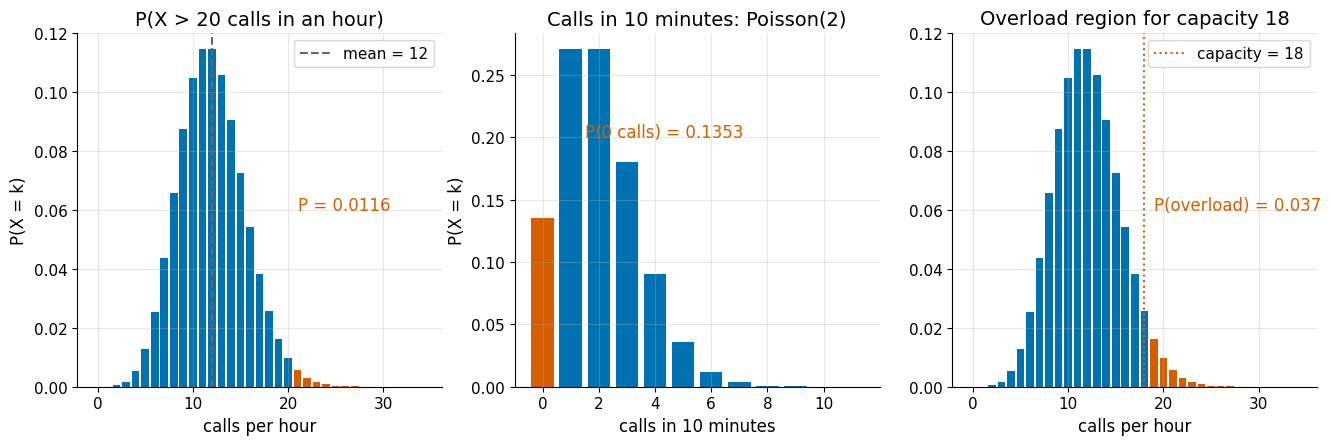

In [16]:
k_values = np.arange(0, 35)
pmf_values = calls_per_hour.pmf(k_values)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

axes[0].bar(k_values, pmf_values, color=MAIN)
tail = k_values > 20
axes[0].bar(k_values[tail], pmf_values[tail], color=HIGHLIGHT)
axes[0].axvline(lam_hour, color=NEUTRAL, linestyle="--", label="mean = 12")
axes[0].set_title("P(X > 20 calls in an hour)")
axes[0].text(21, 0.06, f"P = {p_over_20_code:.4f}", color=HIGHLIGHT, fontsize=12)
axes[0].set_xlabel("calls per hour")
axes[0].set_ylabel("P(X = k)")
axes[0].legend()

small = np.arange(0, 12)
axes[1].bar(small, calls_per_10_min.pmf(small), color=MAIN)
axes[1].bar([0], [p_no_calls_code], color=HIGHLIGHT)
axes[1].set_title("Calls in 10 minutes: Poisson(2)")
axes[1].text(1.5, 0.2, f"P(0 calls) = {p_no_calls_code:.4f}", color=HIGHLIGHT, fontsize=12)
axes[1].set_xlabel("calls in 10 minutes")
axes[1].set_ylabel("P(X = k)")

axes[2].bar(k_values, pmf_values, color=MAIN)
over = k_values > capacity_code
axes[2].bar(k_values[over], pmf_values[over], color=HIGHLIGHT)
axes[2].axvline(capacity_code, color=HIGHLIGHT, linestyle=":", label=f"capacity = {capacity_code:.0f}")
axes[2].set_title("Overload region for capacity 18")
axes[2].text(19, 0.06, f"P(overload) = {calls_per_hour.sf(capacity_code):.3f}", color=HIGHLIGHT, fontsize=12)
axes[2].set_xlabel("calls per hour")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- A busy hour of **more than 20 calls is rare**, about 1 hour in 86 (P about 0.012).
- Any given **10-minute quiet window with no calls at all** happens about **13.5 %** of the time, so idle stretches are normal, not a sign that something broke.
- **Decision:** staff for **18 calls per hour**. The center will be overloaded in under 5 % of hours (3.7 % exactly). Staffing for the average of 12 would overload it in about 42 % of hours.

### 11.6 Second example: server requests
A server gets 3 requests per second on average. The probability of 8 or more requests in a second is $P(X\ge 8)$ with $X\sim\text{Poi}(3)$.

In [17]:
requests = stats.poisson(mu=3)
by_hand = 1 - sum(math.exp(-3) * 3**k / math.factorial(k) for k in range(0, 8))
assert np.isclose(by_hand, requests.sf(7))
print(f"P(8+ requests in a second) = {requests.sf(7):.4f}, about once every {1 / requests.sf(7):.0f} seconds")

P(8+ requests in a second) = 0.0119, about once every 84 seconds


### 11.7 Real data: goals in Premier League matches
Soccer goals are a classic Poisson example: scoring chances are many, each has a low chance of success. We use the 2023/24 English Premier League season (380 matches, source documented in `../data/README.md`). Every match gives two numbers: home goals and away goals. We treat each team's score in a match as one observation, giving 760 observations.

In [18]:
import pathlib
data_path = pathlib.Path("../data/E0_2324.csv")
if not data_path.exists():
    raise FileNotFoundError("Run `python ../data/download_data.py` first to download the dataset.")

matches = pd.read_csv(data_path, usecols=["HomeTeam", "AwayTeam", "FTHG", "FTAG"])
goals = np.concatenate([matches["FTHG"].to_numpy(), matches["FTAG"].to_numpy()])
print(len(matches), "matches,", len(goals), "team scores")
print(f"mean goals per team per match = {goals.mean():.3f}, variance = {goals.var():.3f}")

380 matches, 760 team scores
mean goals per team per match = 1.639, variance = 1.770


The mean and the variance are close, which is what a Poisson predicts. We estimate lambda by the sample mean (the MLE), then compare observed frequencies with the Poisson expectation for 0, 1, 2, ... goals.

In [19]:
lam_goals = goals.mean()                        # MLE of lambda
goal_values = np.arange(0, 8)
observed_counts = np.bincount(goals, minlength=8)[:8]
expected_counts = stats.poisson(lam_goals).pmf(goal_values) * len(goals)

table = pd.DataFrame({"goals": goal_values, "observed": observed_counts, "expected (Poisson)": expected_counts.round(1)})
print(table.to_string(index=False))

 goals  observed  expected (Poisson)
     0       157               147.5
     1       240               241.8
     2       187               198.2
     3       105               108.3
     4        46                44.4
     5        19                14.6
     6         5                 4.0
     7         0                 0.9


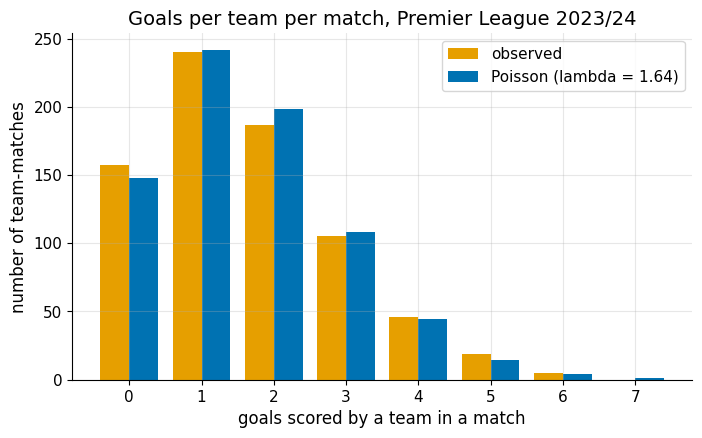

In [20]:
fig, ax = plt.subplots()
width = 0.4
ax.bar(goal_values - width / 2, observed_counts, width=width, color=SIM, label="observed")
ax.bar(goal_values + width / 2, expected_counts, width=width, color=MAIN, label=f"Poisson (lambda = {lam_goals:.2f})")
ax.set_title("Goals per team per match, Premier League 2023/24")
ax.set_xlabel("goals scored by a team in a match")
ax.set_ylabel("number of team-matches")
ax.legend()
plt.show()

**Chi-square goodness of fit (preview).** If the model is right, $\sum (O-E)^2/E$ is approximately chi-square. We merge the tail (5 or more goals) so every expected count is at least 5, and lose one degree of freedom for the estimated lambda. A large p-value means no evidence against the Poisson.

In [21]:
observed_merged = np.append(observed_counts[:5], observed_counts[5:].sum())
poisson_probs = stats.poisson(lam_goals).pmf(np.arange(0, 5))
expected_merged = np.append(poisson_probs, 1 - poisson_probs.sum()) * len(goals)

chi_square = ((observed_merged - expected_merged) ** 2 / expected_merged).sum()
degrees_of_freedom = len(observed_merged) - 1 - 1        # categories - 1 - estimated parameters
p_value = stats.chi2.sf(chi_square, degrees_of_freedom)
print(f"chi-square = {chi_square:.2f}, df = {degrees_of_freedom}, p-value = {p_value:.3f}")

chi-square = 2.36, df = 4, p-value = 0.670


**Reading the result.** The p-value is large, so the data are consistent with a Poisson model of about 1.6 goals per team per match. In practice analysts refine this (teams differ in strength, and home teams score more) but the basic Poisson is a strong first model, and a widely used baseline for match prediction.

## 12. Where it is used

### Statistics
- **Poisson regression** (a GLM) models counts with covariates through a log link.
- **Rate comparison tests:** counts of events in two exposure periods are compared with Poisson-based tests.
- **Dispersion check:** variance-to-mean ratio is the first diagnostic for count data.

### Data science
- **Web traffic and server load:** requests per second, tickets per hour, for capacity planning.
- **Defect counts** per unit of product or per page of text; arrival counts for queueing (Module 11).
- **Event rates in A/B tests** (purchases per user-day).

### ML and AI
- **Count likelihood in recommender and demand models:** Poisson factorization models predict counts of interactions.
- **Poisson loss** (log-link output) in neural nets and gradient boosting for count targets.
- **Spike counts** in neuroscience models and point-process models of events.

## 13. Common pitfalls and misconceptions

- **Overdispersion:** real counts often have variance above the mean (events cluster). Poisson then underestimates the tails; use Negative Binomial.
- **Rate not constant:** traffic is higher at midday than at night; a single lambda fits only a stable window.
- **Window units:** lambda must match the window. 12 per hour is 2 per 10 minutes, not 12.
- **Not independent:** aftershocks, retweets and call retries break independence.
- **Zero-inflated data:** too many zeros (people who can never buy) need a zero-inflated model.
- **sf vs cdf:** `P(X > 20)` is `sf(20)`; `P(X >= 20)` is `sf(19)`.

## 14. Exercises

1. Emails arrive at 6 per hour. What is the probability of exactly 3 emails in an hour? Of none in 30 minutes?
2. The number of typos per page is Poisson with mean 0.8. What is the probability that a page has at least 2 typos?
3. Show that for Poisson($\lambda$), $P(X=k+1)/P(X=k)=\lambda/(k+1)$, and use it to find the mode.
4. A shop has two entrances with 5 and 7 customers per hour. What is the probability that the total in an hour exceeds 15?
5. Using code, find the smallest n for which Binomial(n, 3/n) and Poisson(3) differ by less than 0.001 at every k.
6. A road has 2 accidents per week on average. What is the probability of a week with no accidents, and of 2 weeks in a row with none?
7. (Harder) Events are Poisson with rate 10 per hour; each is "important" independently with probability 0.3. What is the distribution of important events per hour? Verify by simulation.
8. (Harder) Show that if $X\sim\text{Poi}(\lambda_1)$, $Y\sim\text{Poi}(\lambda_2)$ are independent, then $X\mid X+Y=n\sim\text{Bin}(n,\lambda_1/(\lambda_1+\lambda_2))$.

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameter | lambda > 0 (average events per window) |
| Support | k = 0, 1, 2, ... |
| PMF | e^(-lambda) lambda^k / k! |
| Mean | lambda |
| Variance | lambda |
| Skewness | 1 / sqrt(lambda) |
| When to use | counts of independent events at a constant rate in a fixed window |
| `scipy` name | `scipy.stats.poisson(mu=lambda)` |

## Solutions

In [22]:
print("1:", stats.poisson(6).pmf(3), " none in 30 min:", stats.poisson(3).pmf(0))
print("2:", stats.poisson(0.8).sf(1))
print("4:", stats.poisson(12).sf(15))

lam = 3
n_found = None
for n in range(4, 2000):
    ks = np.arange(0, 40)
    if np.max(np.abs(stats.binom.pmf(ks, n, lam / n) - stats.poisson.pmf(ks, lam))) < 0.001:
        n_found = n
        break
print("5: smallest n =", n_found)
print("6:", stats.poisson(2).pmf(0), " two weeks:", stats.poisson(2).pmf(0) ** 2, "=", stats.poisson(4).pmf(0))

important = rng.binomial(rng.poisson(10, size=100_000), 0.3)
print("7: simulated mean/var", important.mean().round(3), important.var().round(3), "(Poisson(3) has both = 3)")

1: 0.08923507835998894  none in 30 min: 0.049787068367863944
2: 0.1912078645890011
4: 0.15558434754981681
5: smallest n = 339
6: 0.1353352832366127  two weeks: 0.018315638888734182 = 0.01831563888873418
7: simulated mean/var 3.005 2.989 (Poisson(3) has both = 3)


**1.** $e^{-6}6^3/3!\approx0.0892$; no emails in 30 minutes: $e^{-3}\approx0.0498$.

**2.** $1-e^{-0.8}(1+0.8)\approx0.1912$.

**3.** $\dfrac{e^{-\lambda}\lambda^{k+1}/(k+1)!}{e^{-\lambda}\lambda^k/k!}=\dfrac{\lambda}{k+1}$. The PMF rises while $\lambda/(k+1)>1$ i.e. $k+1<\lambda$, so the mode is $\lfloor\lambda\rfloor$.

**4.** Total is Poisson(12) by additivity, $P(>15)\approx0.1556$.

**5.** Printed above; convergence is slow in the sense that the error shrinks like $1/n$.

**6.** $e^{-2}\approx0.1353$; two weeks: $e^{-4}\approx0.0183$ (the rate doubles over two weeks).

**7.** Thinning: Poisson(3). The simulated mean and variance are both close to 3.

**8.** $P(X=k\mid X+Y=n)=\dfrac{P(X=k)P(Y=n-k)}{P(X+Y=n)}=\dfrac{\frac{e^{-\lambda_1}\lambda_1^k}{k!}\frac{e^{-\lambda_2}\lambda_2^{n-k}}{(n-k)!}}{\frac{e^{-(\lambda_1+\lambda_2)}(\lambda_1+\lambda_2)^n}{n!}}=\binom nk\Big(\frac{\lambda_1}{\lambda_1+\lambda_2}\Big)^k\Big(\frac{\lambda_2}{\lambda_1+\lambda_2}\Big)^{n-k}$.